# L22 · Evaluator-optimizer: corregir una respuesta hasta que pase

*Advanced Topics in Analytics II - Generative AI* · Instructor: Sergio A. Mora Pardo

En [L19](L19-Parallelization.ipynb) tres revisores **detectaban** los problemas de una respuesta. En el patrón **evaluator-optimizer**, la revisión vuelve al generador como **retroalimentación** y el generador **corrige**, en un ciclo, hasta que el evaluador aprueba o se acaba el número de intentos.

El caso: un cliente de **ACME** perdió su empleo y pregunta qué opciones tiene. La respuesta debe cumplir una rúbrica: cifras de la política, citas, sin promesas de aprobación y corta.

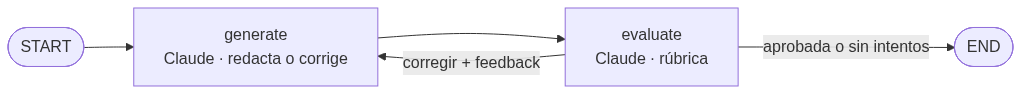

<details><summary>Código Mermaid</summary>

```mermaid
flowchart LR
    S([START]) --> G["generate<br/>Claude · redacta o corrige"]
    G --> V["evaluate<br/>Claude · rúbrica"]
    V -->|"aprobada o sin intentos"| E([END])
    V -->|"corregir + feedback"| G
```

</details>

## Objetivos

1. Construir un ciclo en un grafo con una arista condicional que vuelve atrás.
2. Poner un **tope de intentos** para que el ciclo siempre termine.
3. Escribir un evaluador con salida estructurada y una rúbrica explícita.
4. Pasar la retroalimentación del evaluador al generador.
5. Leer el historial de intentos.

El recorrido realiza **entre 2 y 6 llamadas a Claude Haiku** en la sección 3: 2 por intento, con un máximo de 3 intentos. La sección 1 no llama al modelo.

## 0. Preparación

In [1]:
from dotenv import find_dotenv, load_dotenv
from langchain_anthropic import ChatAnthropic

# find_dotenv sube por las carpetas hasta encontrar el .env de la raíz
load_dotenv(find_dotenv())

model = ChatAnthropic(
    model="claude-haiku-5-5",
    max_tokens=500,
    thinking={"type": "disabled"},
    timeout=60,
    max_retries=2,
)

In [2]:
from pathlib import Path

from pypdf import PdfReader


def policy_text(name):
    """El texto completo de una política: cada una tiene dos páginas y cabe entera en el prompt."""
    path = Path("../datasets") / name
    return "\n\n".join(f"[{name}, p. {n}]\n{page.extract_text()}" for n, page in enumerate(PdfReader(path).pages, 1))

In [3]:
from IPython.display import Image, display


def show(graph):
    """Dibuja el grafo como imagen con el servicio mermaid.ink (necesita conexión a internet)."""
    display(Image(graph.get_graph().draw_mermaid_png()))

## 1. Un ciclo con tope

Sin modelo. Un ciclo es una arista condicional que **vuelve** a un nodo anterior. Sin un tope, un evaluador muy exigente lo haría girar para siempre (y cada vuelta cuesta llamadas). El estado lleva un contador `attempts`; la arista termina cuando el evaluador aprueba **o** se llega a `MAX_ATTEMPTS`.

Aquí el «evaluador» aprueba en el tercer intento, para ver el ciclo sin gastar llamadas.

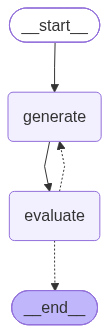

[{'attempt': 1, 'grade': 'corregir'},
 {'attempt': 2, 'grade': 'corregir'},
 {'attempt': 3, 'grade': 'aprobada'}]

In [4]:
import operator
from typing import Annotated, Literal, TypedDict

from langgraph.graph import END, START, StateGraph

MAX_ATTEMPTS = 3


class DraftState(TypedDict, total=False):
    question: str
    draft: str
    feedback: str
    grade: str
    attempts: int
    history: Annotated[list[dict], operator.add]


def fake_generate(state: DraftState) -> dict:
    attempts = state.get("attempts", 0) + 1
    return {"draft": f"borrador {attempts}", "attempts": attempts}


def fake_evaluate(state: DraftState) -> dict:
    grade = "aprobada" if state["attempts"] >= 3 else "corregir"
    return {"grade": grade, "history": [{"attempt": state["attempts"], "grade": grade}]}


def should_continue(state: DraftState) -> Literal["generate", "__end__"]:
    if state["grade"] == "aprobada" or state["attempts"] >= MAX_ATTEMPTS:
        return END
    return "generate"


builder = StateGraph(DraftState)
builder.add_node("generate", fake_generate)
builder.add_node("evaluate", fake_evaluate)
builder.add_edge(START, "generate")
builder.add_edge("generate", "evaluate")
builder.add_conditional_edges("evaluate", should_continue)
loop = builder.compile()
show(loop)

loop.invoke({"question": "prueba"})["history"]

## 2. El generador y el evaluador

El **generador** redacta con la política. Si hay retroalimentación del intento anterior, la incluye en el prompt y corrige.

El **evaluador** aplica una rúbrica con salida estructurada (L2): una calificación cerrada y una retroalimentación concreta. Le pasamos la misma política, para que compare cifras. Usamos `method="json_schema"`, como en el juez de L11, para que la calificación siempre llegue.

In [5]:
from langchain_core.messages import HumanMessage, SystemMessage
from pydantic import BaseModel, Field

POLICY = policy_text("acme_collections_policy.pdf")

RUBRIC = """\
Aprueba solo si la respuesta cumple todo:
1. Las cifras y plazos coinciden con la política (periodo de gracia, carta de terminación, una sola vez).
2. Cada dato de la política lleva su cita [archivo, p. N].
3. No promete aprobaciones ni da asesoría financiera personalizada.
4. Tiene como máximo 90 palabras.
"""


class Feedback(BaseModel):
    """Evaluación de una respuesta a un cliente de ACME."""

    grade: Literal["aprobada", "corregir"] = Field(description="aprobada si cumple toda la rúbrica.")
    feedback: str = Field(description="Qué corregir, punto por punto; vacío si se aprueba.")


evaluator = model.model_copy(update={"max_tokens": 1000}).with_structured_output(Feedback, method="json_schema")


def generate(state: DraftState) -> dict:
    instructions = (
        "Eres el asistente de soporte de ACME. Responde en español usando solo la política y cita cada dato con "
        "[archivo, p. N]."
    )
    request = f"Política:\n{POLICY}\n\nPregunta del cliente: {state['question']}"
    if state.get("feedback"):
        request += f"\n\nTu respuesta anterior:\n{state['draft']}\n\nCorrige esto:\n{state['feedback']}"
    draft = model.invoke([SystemMessage(instructions), HumanMessage(request)]).text
    return {"draft": draft, "attempts": state.get("attempts", 0) + 1}


def evaluate(state: DraftState) -> dict:
    result = evaluator.invoke([
        SystemMessage(f"Eres un revisor de respuestas de ACME.\n{RUBRIC}"),
        HumanMessage(f"Política:\n{POLICY}\n\nPregunta: {state['question']}\n\nRespuesta:\n{state['draft']}"),
    ])
    return {
        "grade": result.grade,
        "feedback": result.feedback,
        "history": [{"attempt": state["attempts"], "grade": result.grade, "feedback": result.feedback, "draft": state["draft"]}],
    }

## 3. El ciclo con el modelo

El mismo grafo de la sección 1, con los nodos reales. Cada intento cuesta **2 llamadas**: generar y evaluar.

In [6]:
builder = StateGraph(DraftState)
builder.add_node("generate", generate)
builder.add_node("evaluate", evaluate)
builder.add_edge(START, "generate")
builder.add_edge("generate", "evaluate")
builder.add_conditional_edges("evaluate", should_continue)
optimizer = builder.compile()

result = optimizer.invoke({"question": "Perdí mi empleo y no puedo pagar la cuota de mi crédito. ¿Qué opciones tengo?"})

for step in result["history"]:
    print(f"Intento {step['attempt']} · {step['grade']}")
    if step["feedback"]:
        print("   feedback:", step["feedback"][:300])
print("\nRespuesta final:\n", result["draft"])

Intento 1 · corregir
   feedback: 1) La respuesta supera las 90 palabras y queda cortada al final ("puedes ac"); debe acortarse y terminarse. 2) El punto 3 (acuerdo de pago) no tiene cita [archivo, p. N] para sus datos (1 a 30 días, acuerdos desde la app), que están en p. 1. 3) Revisar que no se prometa aprobación: frases como "Segú
Intento 2 · aprobada

Respuesta final:
 Lamento que estés pasando por esta situación. Según la política de ACME, estas son tus opciones:

**1. Periodo de gracia por desempleo**
- Si perdiste tu empleo, puedes pedir un periodo de gracia de hasta 3 meses en el pago de capital. Durante ese periodo pagas solo intereses y seguro [acme_collections_policy.pdf, p. 2].
- Debes presentar la carta de terminación del contrato laboral dentro de los 30 días siguientes a la terminación [acme_collections_policy.pdf, p. 2].
- Este beneficio se otorga una sola vez durante la vida del crédito [acme_collections_policy.pdf, p. 2].

**2. Reestructuración de tu crédito**
- Si tie

Lee el historial: ¿cuántos intentos hicieron falta? ¿El feedback del evaluador fue concreto (una cifra, una cita que falta, una frase que promete algo) o genérico? En la salida guardada aprobó en el segundo intento, pero en otras ejecuciones **no aprobó en ninguno de los 3**: la respuesta pasaba de 90 palabras y en cada ronda el evaluador pedía además algo nuevo (más condiciones de la política), que alargaba el texto. Una rúbrica con exigencias que se contradicen (corta **y** completa) puede hacer girar el ciclo hasta el tope. Si llega a 3 intentos sin aprobar, la respuesta final **no** está aprobada: la aplicación debería mandarla a revisión humana (L20) en lugar de enviarla.

## 4. Cuándo vale la pena

| | Una llamada | Evaluator-optimizer |
|---|---|---|
| Llamadas | 1 | 2 a 2 × `MAX_ATTEMPTS` |
| Calidad | La del primer intento | Mejora si la rúbrica es clara y el feedback concreto |
| Riesgo | Errores sin detectar | Un evaluador que aprueba todo, o uno que nunca aprueba |

Úsalo cuando existe un criterio claro de «bien hecho» que el modelo puede verificar y cuando un humano corregiría el texto con comentarios. Antes de confiar en el evaluador, **calíbralo** con respuestas revisadas por personas, como el juez de L11.

## Práctica breve

1. Cambia `MAX_ATTEMPTS` a 1. ¿Qué devuelve el grafo si el primer borrador no se aprueba?
2. Agrega a la rúbrica una regla: la respuesta debe terminar ofreciendo el canal para solicitar el periodo de gracia. ¿Cuántos intentos hacen falta ahora?
3. Si el último intento no se aprueba, agrega un nodo que marque la respuesta como `revisión humana` en lugar de terminar.
4. Usa los tres revisores de L19 como evaluador y combina sus veredictos.

## Referencias

- **Anthropic**, [Building effective agents](https://www.anthropic.com/engineering/building-effective-agents): *evaluator-optimizer*.
- [Workflows y agentes en LangGraph](https://docs.langchain.com/oss/python/langgraph/workflows-agents#evaluator-optimizer)